<a class="anchor" id="0.1"></a>
# **Table of Contents**

- 1. [Setup](#1)
- 2. [Data Preparation](#2)
<!--     - 2.1 [Data Preparation for LSTM](#2.1) -->
- 3. [EDA](#3)
- 4. [Anomaly Detection](#4)
- 5. [Anomaly Creation](#5)
- 6. [Genetic Algoritm Otimization](#6)


# **1. SetUp** <a class="anchor" id="1"></a>

[Table of Contents](#0.1)

In [1]:
# Data Manipulation and Analysis
import numpy as np
import pandas as pd
from tqdm import tqdm 
import random

#Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn for Machine Learning
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_recall_curve


# Read a CSV file into a Pandas DataFrame
df = pd.read_csv("/kaggle/input/mobileum/jul_aug_sep_oct_2022_msc_1.csv", sep=";")

# Convert Start Date and Start Hour into a datetime object and set as index
df['TIMESTAMP'] = pd.to_datetime(df['Start Date'] + ' ' + df['Start Hour'].astype(str), format='%d/%m/%Y %H')
# df.set_index("TIMESTAMP", inplace=True)

# Clean the #Events column, remove any non-numeric characters, fill NaNs with 0, and convert to integer
df['#Events'] = df['#Events'].str.replace(r'[^\d.-]', '', regex=True)
df['#Events'] = df['#Events'].fillna(0)
df['#Events'] = pd.to_numeric(df['#Events']).astype(int)

# Drop unnecessary columns
# df.drop(columns=['Datasource', 'Start Date', 'Start Hour'], inplace=True) 
df.drop(columns=['Datasource', 'Start Date', 'Start Hour', 'Event Duration'], inplace=True)

# Drop duplicates
df.drop_duplicates(inplace=True)
# df=df.reset_index()

In [2]:
filters = pd.read_csv("/kaggle/input/mobileum-empty-agg/not_empty_combinations.csv")

In [3]:
def contain_condition(df, conditions):
    if not conditions:
        return False
    pd_conditions = " & ".join([f'`{key}` == "{value}"' for key, value in conditions.items()])
    return df.eval(pd_conditions).any()

# **4. Anomaly Creation** <a class="anchor" id="4"></a>

[Table of Contents](#0.1)

In [4]:
def filter_and_aggregate(df, filter_conditions, hierarchy=False):
    """
    Filters the DataFrame based on given conditions and aggregates by summing up a specified column.
    
    Args:
    - df: The original DataFrame.
    - filter_conditions: A dictionary where keys are column names and values are the values to filter on.
    
    Returns:
    - A new DataFrame with the filtered and aggregated data.
    """
    # Apply the filter conditions
    df_fil = df.copy()
    
    for col, val in filter_conditions.items():
        df_fil = df_fil[df_fil[col] == val]
    
    # Drop the columns used for filtering
    df_fil.drop(columns=list(filter_conditions.keys()), inplace=True)
    
    # Group by 'TIMESTAMP' and sum up the '#Events' column
    if hierarchy:
        df_agg = df_fil.groupby('TIMESTAMP')[['#Events','Anomaly']].sum().reset_index()
    else:
        df_agg = df_fil.groupby('TIMESTAMP')['#Events'].sum().reset_index()
    
    return df_agg


In [5]:
def generate_anomaly(mean, std, lower_bound=0):
    """
    Generate a random anomaly value.
    
    Parameters:
    mean (float): The mean value of the normal data.
    std (float): The standard deviation of the normal data.
    lower_bound (int): The minimum value an anomaly can take, inclusive. Default is 0.
    
    Returns:
    int: An anomalous data point.
    """
    print(mean, std)
    upper_normal = mean + 3 * std
    lower_normal = max(mean - (3 * std), lower_bound)
    
    
    # Choose between an anomaly below or above the normal range.
    anomaly_value = np.random.choice([upper_normal, lower_normal])
    return anomaly_value


In [6]:
def insert_anomaly(df, df_anomaly, index, unique_conditions, plot=False):
    # Identify time-stamp at the given index
    ts = df_anomaly.iloc[index]['TIMESTAMP']
    
    # Define window for calculating std and mean
    start = max(index - 84, 0)
    end = min(index + 83, len(df_anomaly) - 1)
    
    print(start, end)
    print(ts)
    # Calculate standard deviation and mean within the window and if the window is equal to 1
    if start != end:
        std = df_anomaly[start:end]['#Events'].std()
        mean = df_anomaly[start:end]['#Events'].mean()
        anomaly_value = generate_anomaly(mean, std)
    else:
        value = std= mean = df_anomaly.iloc[start]['#Events']

        anomaly_value = np.random.choice([max(value-value/2,0), value*3/2])
    

    
    mask = (df['TIMESTAMP'] == ts)

    # Apply additional conditions from dictionary of conditions
    for col, val in unique_conditions.items():
        mask &= (df[col] == val)

    # This mask can now be used to filter df
    rows_with_ts = df[mask]

    # Sum of '#Events' for these rows
    sum_events = rows_with_ts['#Events'].sum()

    # Calculate multiplier
    m = anomaly_value / sum_events

    # Check if the 'Anomaly' column exists
    if 'Anomaly' not in df.columns:
        df['Anomaly'] = 0
    
    print(len(df.loc[mask, '#Events']))
    print(df.loc[mask, '#Events'])
    # Apply multiplier and round to integer values
    df.loc[mask, '#Events'] = (rows_with_ts['#Events'] * m).round().astype(int)
    print(df.loc[mask, '#Events'])
    # Update 'Anomaly' column only for rows where '#Events' 
    df.loc[mask, 'Anomaly'] = 1
    
    
    if plot == True:
#         print(f"Anomaly value: {anomaly_value}")
        plt.figure(figsize=(10, 6))
        plt.plot(df_original["TIMESTAMP"], df_original["#Events"], label="Events", marker='o', linestyle='-', markersize=4)
        plt.scatter(ts, anomaly_value, color='red', s=100, label='Anomaly', zorder=5)
        plt.xlabel('TIMESTAMP')
        plt.ylabel('#Events')
        plt.title('Visualization of #Events with Anomaly Inserted')
        plt.legend()
        plt.grid(True)
        plt.show()

    
    # Print actual and anomaly values
    actual_value = df_anomaly.iloc[index]['#Events']
    anomaly_value_df = df.loc[mask, '#Events'].sum()
#     print("actual_value:", actual_value, "Anomaly_value:", anomaly_value,"Anomaly_value_df:", anomaly_value_df, "Mean:", mean, "Std:", std)
    
    return ts, mean, std, anomaly_value, anomaly_value_df, actual_value, unique_conditions

In [7]:
def insert_nanomaly(df, n_anomalies, plot=False):
    
    columns = ['Call Type', 'Event Type', 'Subscriber Type', 'Traffic Type', 'Service Type', 'Partner Description']
    
    # Store anomalies for plotting
    anomaly_records = []
    
    # Store unique conditions to ensure they are not repeated
    used_conditions = set()
    
    df_anomaly = df.copy()
    
    # Check if the 'Anomaly' column exists
    if 'Anomaly' not in df_anomaly.columns:
        df_anomaly['Anomaly'] = 0
    
    for _ in tqdm(range(n_anomalies), desc='Inserting anomalies'):
            while True:
                # Ensure that the same new_columns and unique_conditions are not generated again
                new_columns = [col for col in columns if random.random() < 0.5]
                unique_conditions = {col: random.choice(df[col].unique()) for col in new_columns}
                conditions_tuple = tuple(sorted(unique_conditions.items()))  # Need to convert to a hashable type to store in a set

                if conditions_tuple not in used_conditions:
                    

                    # Retry if df_fil is empty, otherwise, break the loop
                    if contain_condition(filters, unique_conditions):
                        df_fil = filter_and_aggregate(df, unique_conditions)
                        used_conditions.add(conditions_tuple)
                        index = random.choice(df_fil.index)
                        ts, mean, std, anomaly_value, anomaly_value_df, actual_value, conditions = insert_anomaly(df_anomaly, df_fil, index, unique_conditions, plot=False)
                        anomaly_records.append((ts, mean, std, anomaly_value, anomaly_value_df, actual_value, conditions))
                        break  # Successfully inserted an anomaly, can exit loop
                    else:
                        print("This aggregation is empty, retrying with new unique conditions.")
    
    
    anomalies_info_df = pd.DataFrame(anomaly_records, columns=['TIMESTAMP', 'Mean', 'STD', 'Anomaly Value', 'Anomaly Value from DF', 'Actual Value', 'Used Conditions'])
    aux= filter_and_aggregate(df_anomaly, {}, True)
    # Merge dataframes based on timestamp
    mask = aux["TIMESTAMP"].isin(anomalies_info_df["TIMESTAMP"])
    filtered_aux = aux[mask]

    if plot:
        plt.figure(figsize=(10, 6))
        plt.plot(aux["TIMESTAMP"], aux["#Events"], label="Events", marker='o', linestyle='-', markersize=4)

        # Extract timestamps and anomaly values for plotting
#         ts_values, anomaly_values = zip(*anomaly_records) if anomaly_records else ([], [])
        plt.scatter(filtered_aux["TIMESTAMP"], filtered_aux["#Events"], color='red', s=100, label='Anomaly', zorder=5)

        plt.xlabel('TIMESTAMP')
        plt.ylabel('#Events')
        plt.title('Visualization of #Events with Anomaly Inserted')
        plt.legend()
        plt.grid(True)
        plt.show()
    
#     ?<create a dataframe which store the (ts, mean, std, anomaly_value, anomaly_value_df, actual_value and used_conditions)
    

    # Optional: print out the anomaly records for debugging
#     print(anomaly_records)
    
    return df_anomaly, anomalies_info_df


In [8]:
df.describe()

,#Events,TIMESTAMP
count,9.584800e+05,958480
mean,2.395870e+03,2022-08-31 16:35:17.711793408
min,0.000000e+00,2022-07-18 00:00:00
25%,2.000000e+00,2022-08-09 20:00:00
50%,9.000000e+00,2022-09-01 00:00:00
75%,5.900000e+01,2022-09-22 17:00:00
max,3.053227e+06,2022-10-13 21:00:00
std,3.119447e+04,NaN


1. get the anomaly_value and the ts with the function. 
2. go to the original df get all the rows with the same ts (TIMESTAMP)
3. from all the row calculate the sum of column (#Events)
4. calculate the multiplier witch m = anomaly_value/ sum of column (#Events)
5. use the multiplier to all rows of the #Events and do the round to get int
6. Create an new columns witch name "Anomaly" with 0 or 1, which all row which has column 
7. gerate an orignal and modified df

Inserting anomalies:   1%|          | 1/105 [00:00<00:30,  3.45it/s]

22 156
2022-09-29 08:00:00
4.440298507462686 3.7607214034189096
2
792379    3
792544    1
Name: #Events, dtype: int64
792379    0
792544    0
Name: #Events, dtype: int64
This aggregation is empty, retrying with new unique conditions.
This aggregation is empty, retrying with new unique conditions.
This aggregation is empty, retrying with new unique conditions.
This aggregation is empty, retrying with new unique conditions.
This aggregation is empty, retrying with new unique conditions.


Inserting anomalies:   2%|▏         | 2/105 [00:01<01:23,  1.24it/s]

1411 1578
2022-09-18 07:00:00
17613.035928143712 11029.575213773727
3
669288    17838
669333       25
669545      408
Name: #Events, dtype: int64
669288    49500
669333       69
669545     1132
Name: #Events, dtype: int64
1376 1543
2022-09-16 20:00:00
6746.706586826347 5397.314849262065


Inserting anomalies:   3%|▎         | 3/105 [00:02<01:12,  1.40it/s]

2
653988    7219
654368     124
Name: #Events, dtype: int64
653988    22551
654368      387
Name: #Events, dtype: int64


... (200 outputs left out)

Inserting anomalies:  99%|█████████▉| 104/105 [01:21<00:00,  1.37it/s]

1643 1810
2022-09-27 23:00:00
517628.39520958083 474198.83167985734
7
776918    12584
777026        2
777162    14466
777234    13347
777244        2
777304       39
777353    75645
Name: #Events, dtype: int64
776918     210327
777026         33
777162     241782
777234     223079
777244         33
777304        652
777353    1264318
Name: #Events, dtype: int64
This aggregation is empty, retrying with new unique conditions.


Inserting anomalies: 100%|██████████| 105/105 [01:21<00:00,  1.29it/s]

1762 1929
2022-10-02 22:00:00
856.6646706586827 683.3802026212642
1
832743    510
Name: #Events, dtype: int64
832743    0
Name: #Events, dtype: int64


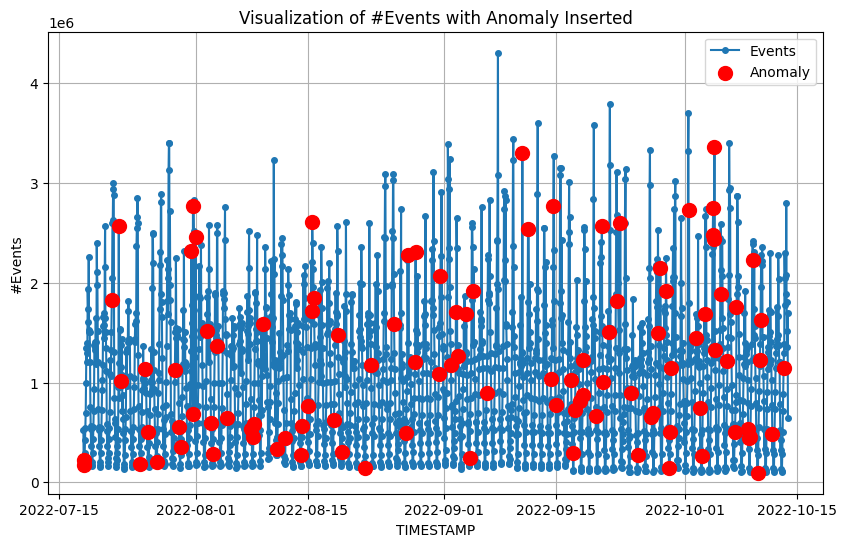

In [22]:
df_anomaly, df_info = insert_nanomaly(df, 105, plot=True)

In [11]:
df_anomaly = pd.read_csv("/kaggle/input/mobileum/df_anomaly.csv")

In [23]:
df_anomaly

,Call Type,Event Type,Subscriber Type,Traffic Type,Service Type,Partner Description,#Events,TIMESTAMP,Anomaly
0,SMS,ORIGINATED,Postpaid,OFF-NET,NOT-ROAMING,P_0001,105,2022-07-18 00:00:00,0
1,VOICE,CALL FORWARD,Application,INT,NOT-ROAMING,P_0001,16,2022-07-18 00:00:00,0
2,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0002,7,2022-07-18 00:00:00,0
3,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0003,15,2022-07-18 00:00:00,0
4,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0004,1,2022-07-18 00:00:00,0
...,...,...,...,...,...,...,...,...,...
958783,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0280,30,2022-10-13 21:00:00,0
958784,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0079,265,2022-10-13 21:00:00,0
958785,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0102,6,2022-10-13 21:00:00,0
958786,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0022,3,2022-10-13 21:00:00,0


In [24]:
df_anomaly.Anomaly.sum()

6321

In [25]:
900000 * 0.05

45000.0

In [26]:
df_anomaly.to_csv("/kaggle/woking/df_anomaly.csv", index=False)

In [42]:
df_info.iloc[3]

TIMESTAMP                                          2022-09-04 04:00:00
Mean                                                     148192.491018
STD                                                       81396.099586
Anomaly Value                                                      0.0
Anomaly Value from DF                                                0
Actual Value                                                     46345
Used Conditions          {'Call Type': 'VOICE', 'Traffic Type': 'INT'}
Name: 3, dtype: object

In [30]:
size = len(df[df["#Events"] != df_anomaly["#Events"]])
print(f"Size of number o anomalies inserted into desaggregated df: {size}")

Size of number o anomalies inserted into desaggregated df: 6317


## Number of examples (rows) on aggreagated with all features with return not an empty dataframe

In [31]:
row_plus_two = len(filters[filters["Number of examples (rows)"]>2])
row_equal_two = len(filters[filters["Number of examples (rows)"]==2])
row_one = len(filters[filters["Number of examples (rows)"]==1])

print(f"Dataframe with more than 2 rows: {row_plus_two}\nDataframe with 2 rows: {row_equal_two}\nDataframe with one row: {row_one} ")

Dataframe with more than 2 rows: 1374
Dataframe with 2 rows: 54
Dataframe with one row: 127 


### Selecting one df_anomaly and analysis how this affect global and locally on the dataset

In [32]:
index = np.random.choice(range(len(df_info)-1))
center_ts = df_info.iloc[index]["TIMESTAMP"]
condictions = df_info.iloc[index]["Used Conditions"]
(index, center_ts, condictions)

(58,
 Timestamp('2022-09-25 04:00:00'),
 {'Call Type': 'SMS', 'Event Type': 'TERMINATED', 'Traffic Type': 'OFF-NET'})

### Random select one anomaly from generated anomalies

In [112]:
df_info[df_info.STD > 200000]["Used Conditions"]

6      {'Call Type': 'SMS', 'Traffic Type': 'ON-NET',...
16     {'Call Type': 'SMS', 'Service Type': 'NOT-ROAM...
18                          {'Event Type': 'TERMINATED'}
31     {'Call Type': 'VOICE', 'Service Type': 'NOT-RO...
39                                  {'Call Type': 'SMS'}
44                                {'Call Type': 'VOICE'}
47     {'Event Type': 'TERMINATED', 'Subscriber Type'...
56     {'Call Type': 'SMS', 'Event Type': 'TERMINATED...
77     {'Event Type': 'TERMINATED', 'Service Type': '...
103    {'Event Type': 'TERMINATED', 'Traffic Type': '...
Name: Used Conditions, dtype: object

In [113]:
df_info.iloc[16]

TIMESTAMP                                              2022-08-01 00:00:00
Mean                                                         654102.790419
STD                                                          554212.151997
Anomaly Value                                               2316739.246409
Anomaly Value from DF                                              2316751
Actual Value                                                        711399
Used Conditions          {'Call Type': 'SMS', 'Service Type': 'NOT-ROAM...
Name: 16, dtype: object

In [114]:
# index = np.random.choice(range(len(df_info)-1))
index = 16
center_ts = df_info.iloc[index]["TIMESTAMP"]
conditions = df_info.iloc[index]["Used Conditions"]
static_value = list(conditions.values())[0]
column = list(conditions.keys())[0]
print(f" INDEX = {index} \n timestamp Selected: {center_ts} \n Conditions: {conditions} \n FIX filter: {static_value} => {column}")

 INDEX = 16 
 timestamp Selected: 2022-08-01 00:00:00 
 Conditions: {'Call Type': 'SMS', 'Service Type': 'NOT-ROAMING'} 
 FIX filter: SMS => Call Type


In [115]:
## Reducing the redundancy to with number of rows equals 2110
filters_fil =filters[(filters[column]==static_value) &(filters["Number of examples (rows)"]==2110)]

## Remove all columns with unique values
rm_columns = list(filters_fil.columns[filters_fil.nunique() == 1])

new_filters = filters_fil.drop(rm_columns, axis = 1)
index = np.random.choice(len(new_filters)-1)
plot_filters = new_filters.iloc[index].values
print(f"Df after filtering {column} => {static_value} : \n{filters_fil}")
print(f"After removing all columns with unique values: \n{new_filters}")
print(f"Columns with unique values: {rm_columns}")
print(f"New filters to use in plot: {plot_filters}")

Df after filtering Call Type => SMS : 
    Call Type  Event Type Subscriber Type Traffic Type Service Type  \
0         SMS  ORIGINATED        Postpaid      OFF-NET  NOT-ROAMING   
1         SMS  ORIGINATED        Postpaid          INT  NOT-ROAMING   
2         SMS  ORIGINATED        Postpaid       ON-NET  NOT-ROAMING   
167       SMS  ORIGINATED       Roamer In          INT  NOT-ROAMING   
322       SMS  ORIGINATED         Prepaid      OFF-NET  NOT-ROAMING   
..        ...         ...             ...          ...          ...   
500       SMS  TERMINATED       Roamer In          INT  NOT-ROAMING   
503       SMS  TERMINATED       Roamer In          INT  NOT-ROAMING   
700       SMS  TERMINATED         Prepaid      OFF-NET  NOT-ROAMING   
701       SMS  TERMINATED         Prepaid          INT  NOT-ROAMING   
702       SMS  TERMINATED         Prepaid       ON-NET  NOT-ROAMING   

    Partner Description  Number of examples (rows)  
0                P_0001                       2110  
1 

In [116]:
df_anomaly_filters = df_anomaly[(df_anomaly["TIMESTAMP"]==center_ts) & (df_anomaly[column]==static_value)]
rm_columns = list(df_anomaly_filters.columns[df_anomaly_filters.nunique() == 1])
df_anomaly_new_filters = df_anomaly_filters.drop(rm_columns, axis=1)

### Desagreggated dataframe from aggregation and Possible aggreation after filters with 2110 rows (which include all timestamps) 

In [117]:
print(df_anomaly_new_filters)
print("\n\n")
print(new_filters)
print("\n\n")

print(len(df_anomaly_new_filters), len(new_filters))

        Event Type Subscriber Type Traffic Type Partner Description  #Events
145194  ORIGINATED       Roamer In          INT              P_0073        7
145213  TERMINATED       Roamer In          INT              P_0138      430
145214  TERMINATED       Roamer In          INT              P_0082       33
145215  TERMINATED       Roamer In          INT              P_0021      261
145216  TERMINATED       Roamer In          INT              P_0022       23
...            ...             ...          ...                 ...      ...
145615  TERMINATED       Roamer In          INT              P_0210       20
145616  TERMINATED       Roamer In          INT              P_0139     3599
145617  TERMINATED       Roamer In          INT              P_0115      482
145618  TERMINATED       Roamer In          INT              P_0262       26
145619  TERMINATED       Roamer In          INT              P_0207        3

[264 rows x 5 columns]



     Event Type Subscriber Type Traffic Type Part

In [118]:
import matplotlib.pyplot as plt

def plot_figure(df_anomaly, df_original, center_ts, conditions, title_add):
    df_anomaly = df_anomaly.reset_index()

    # Encontrando o índice do timestamp central
    center_index = df_anomaly[df_anomaly["TIMESTAMP"] == center_ts].index[0]

    low = max(center_index - 50, 0)
    high = min(center_index + 50, len(df_anomaly) - 1)

    plot_df_anomaly = df_anomaly.iloc[low:high]
    plot_df_original = df_original.iloc[low:high]

    title = ', '.join(map(str, conditions.values()))

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.plot(plot_df_original['TIMESTAMP'], plot_df_original['#Events'], label='Original', marker='o')
    ax.plot(plot_df_anomaly['TIMESTAMP'], plot_df_anomaly['#Events'], label='Anomalia', marker='x')
    ax.set_title(f"{title_add}: {title}")
    ax.set_xlabel('Timestamp')
    ax.set_ylabel('#Eventos')
    ax.legend()

    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [127]:
import matplotlib.pyplot as plt

def plot_figure(df_anomaly, df_original, center_ts, conditions, title_add):
    df_anomaly = df_anomaly.reset_index()

    # Find the index of the center timestamp
    center_index = df_anomaly[df_anomaly["TIMESTAMP"] == center_ts].index[0]

    low = max(center_index - 25, 0)
    high = min(center_index + 25, len(df_anomaly) - 1)

    plot_df_anomaly = df_anomaly.iloc[low:high]
    plot_df_original = df_original.iloc[low:high]

    title = ', '.join(map(str, conditions.values()))

    fig, ax = plt.subplots(figsize=(12, 6))

    # Plot original and anomaly data
    ax.plot(plot_df_original['TIMESTAMP'], plot_df_original['#Events'], label='Original', marker='o')
    ax.plot(plot_df_anomaly['TIMESTAMP'], plot_df_anomaly['#Events'], label='Anomalia', marker='x')

    # Add a dashed red circle at the center timestamp
    ax.scatter(
        center_ts, 
        df_anomaly.loc[center_index, '#Events'], 
        edgecolors='red', 
        facecolors='none', 
        s=800,  # Size of the circle
        linewidths=8,  # Line thickness
        linestyle='dashed',  # Dashed line
        label='Anomalia Usada'
    )

    ax.set_title(f"{title_add}: {title}")
    ax.set_xlabel('Timestamp')
    ax.set_ylabel('#Eventos')
    ax.legend()

    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [128]:
df_original_agg = filter_and_aggregate(df, {}, False)
df_original_cond = filter_and_aggregate(df, condictions, False)

df_anomaly_agg = filter_and_aggregate(df_anomaly, {}, False)
df_anomaly_cond = filter_and_aggregate(df_anomaly, condictions, False)

In [129]:
center_ts

Timestamp('2022-08-01 00:00:00')

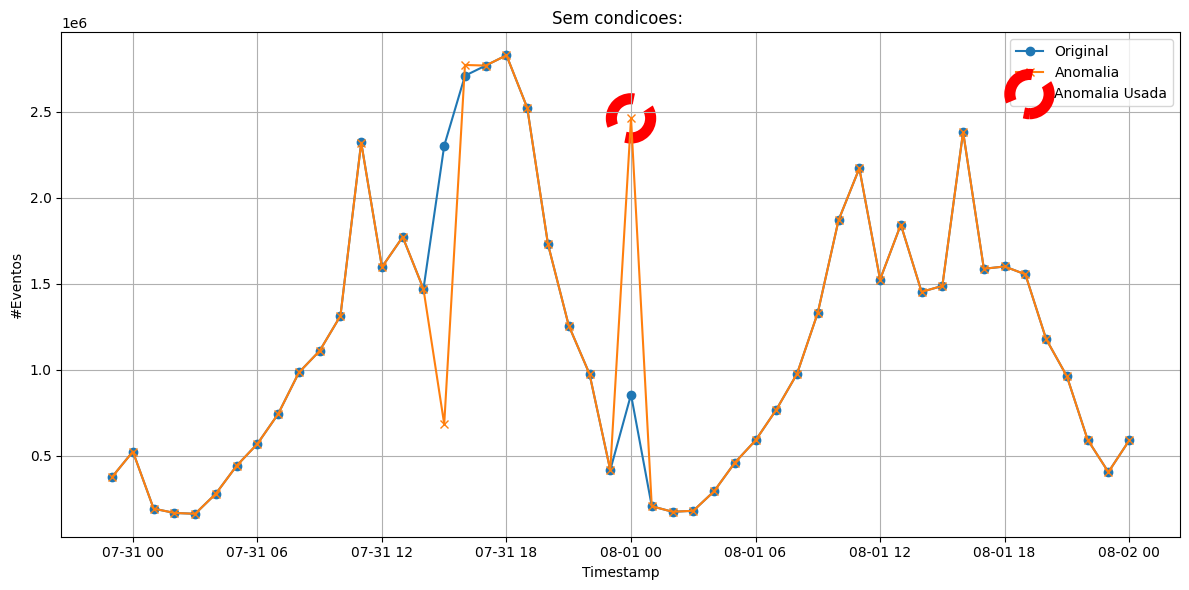

In [130]:
plot_figure(df_anomaly_agg, df_original_agg, center_ts, {}, "Sem condicoes")

In [131]:
conditions

{'Call Type': 'SMS', 'Service Type': 'NOT-ROAMING'}

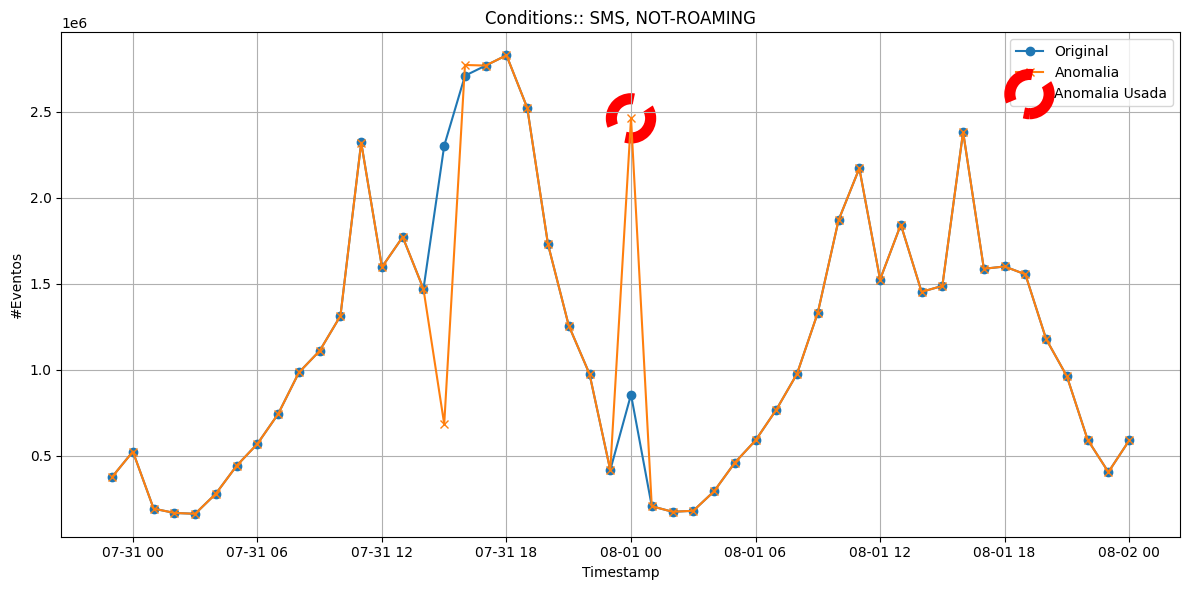

In [138]:
plot_figure(df_anomaly_agg, df_original_agg, center_ts, {'Call Type': 'SMS', 'Service Type': 'NOT-ROAMING'},  "Conditions:")

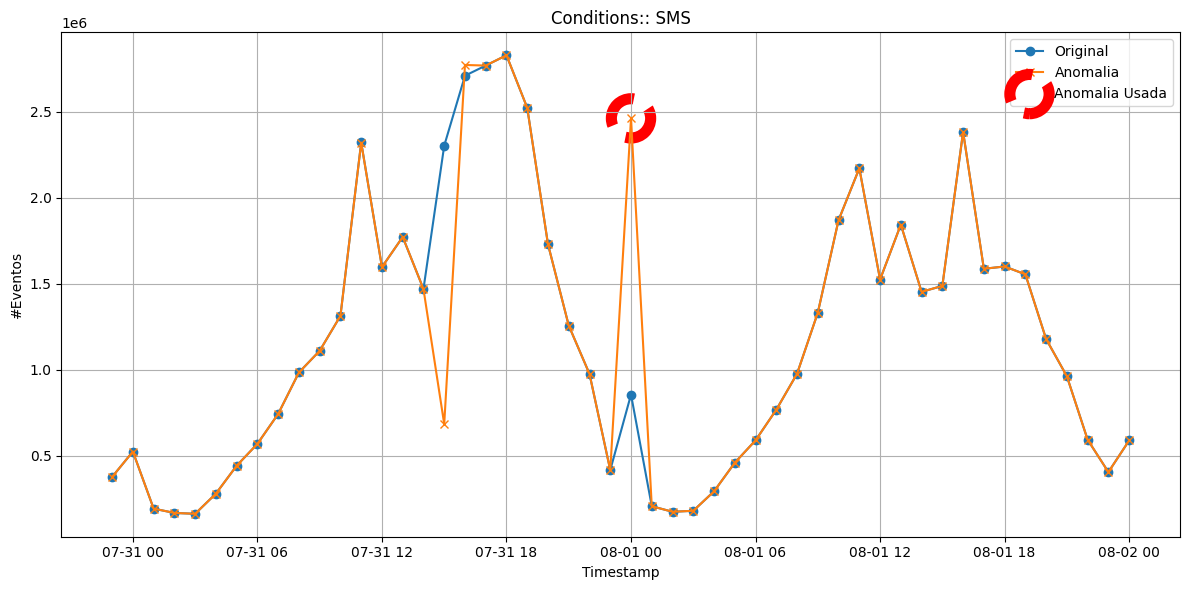

In [139]:
plot_figure(df_anomaly_agg, df_original_agg, center_ts, {'Call Type': 'SMS'},  "Conditions:")

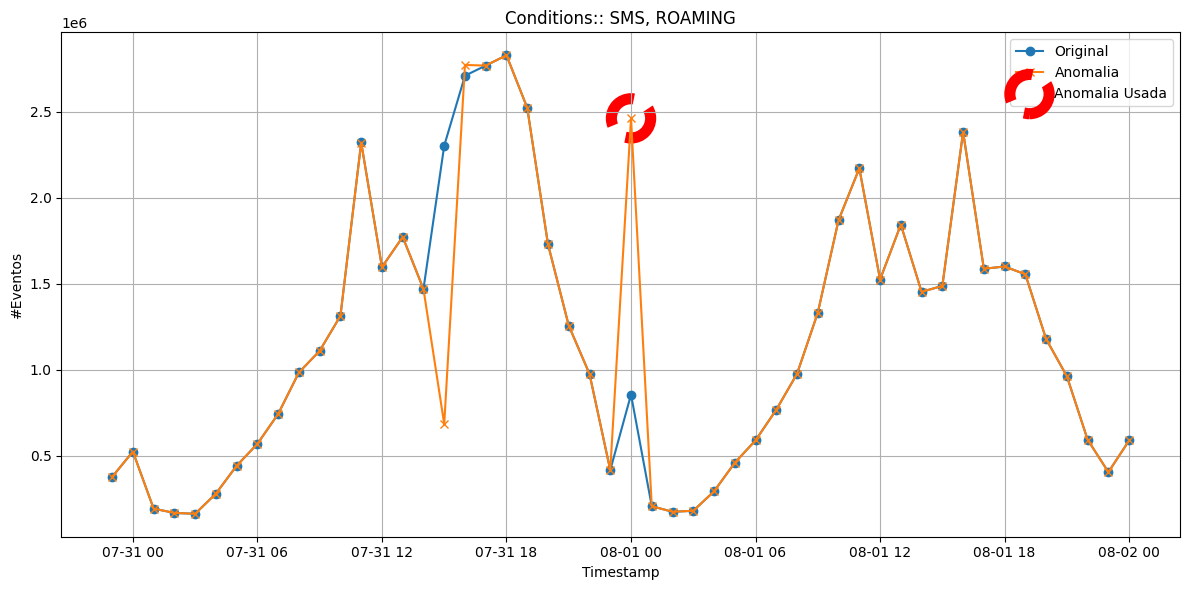

In [140]:
plot_figure(df_anomaly_agg, df_original_agg, center_ts, {'Call Type': 'SMS', 'Service Type': 'ROAMING'}, "Conditions:")

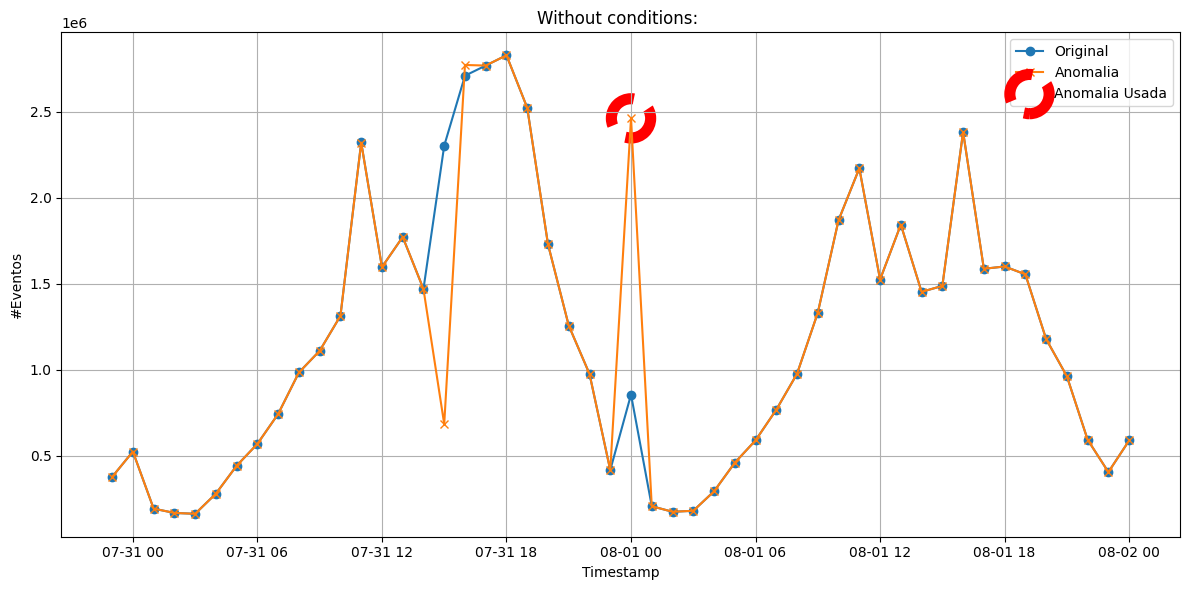

In [141]:
plot_figure(df_anomaly_agg, df_original_agg, center_ts, {}, "Without conditions")

In [142]:
available_categories = {
    'Call Type': df['Call Type'].unique().tolist(),
    'Event Type': df['Event Type'].unique().tolist(),
    'Subscriber Type': df['Subscriber Type'].unique().tolist(),
    'Traffic Type': df['Traffic Type'].unique().tolist(),
    'Service Type': df['Service Type'].unique().tolist(),
    'Partner Description': df['Partner Description'].unique().tolist(),
    'STOP': False
}


def revert_key_value_mapping(available_categories):
    reversed_mapping = {}
    for key, values in available_categories.items():
        if isinstance(values, list):  # Ensure the value is iterable
            for value in values:
                if value not in reversed_mapping:
                    reversed_mapping[value] = []
                reversed_mapping[value].append(key)
        else:
            # Handle non-list values (like the 'STOP' flag)
            value = values
            if value not in reversed_mapping:
                reversed_mapping[value] = []
            reversed_mapping[value].append(key)
    return reversed_mapping

In [143]:
rt_available_categories = revert_key_value_mapping(available_categories)

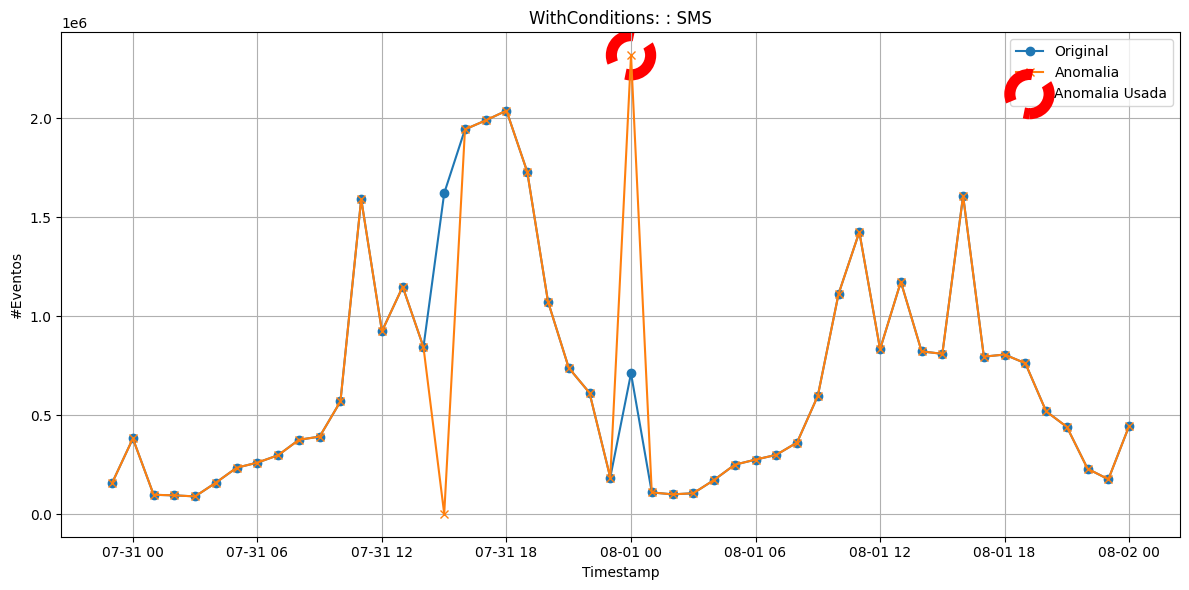

In [144]:
dictionary = {column:static_value}
df_original_cond = filter_and_aggregate(df, dictionary, False)
df_anomaly_cond = filter_and_aggregate(df_anomaly, dictionary, False)
plot_figure(df_anomaly_cond, df_original_cond, center_ts, dictionary, "WithConditions: ")

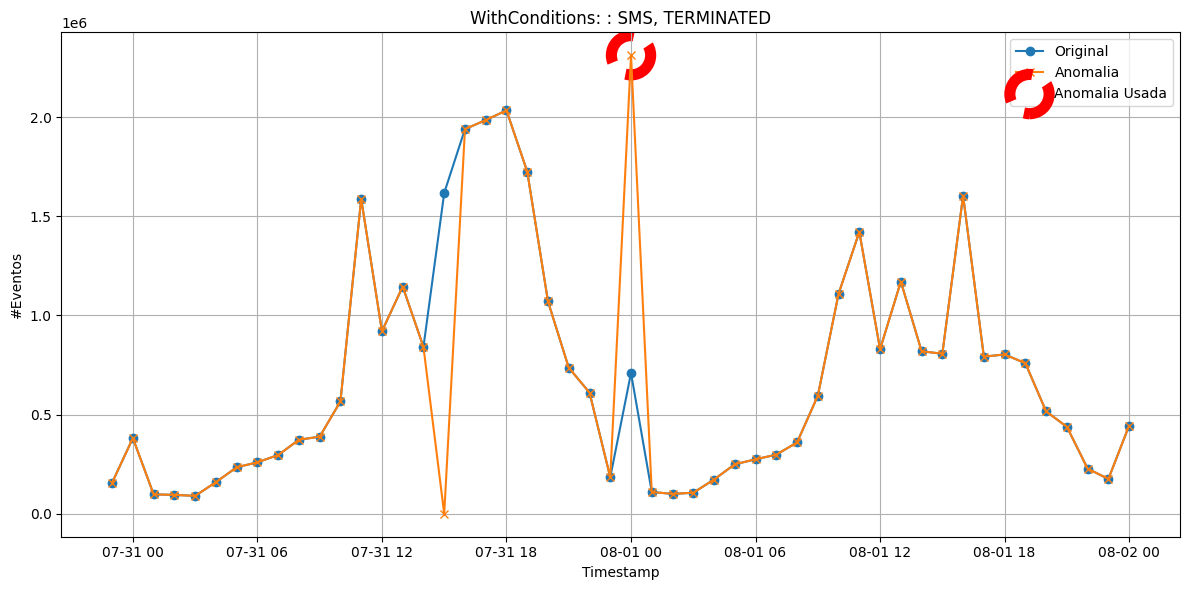

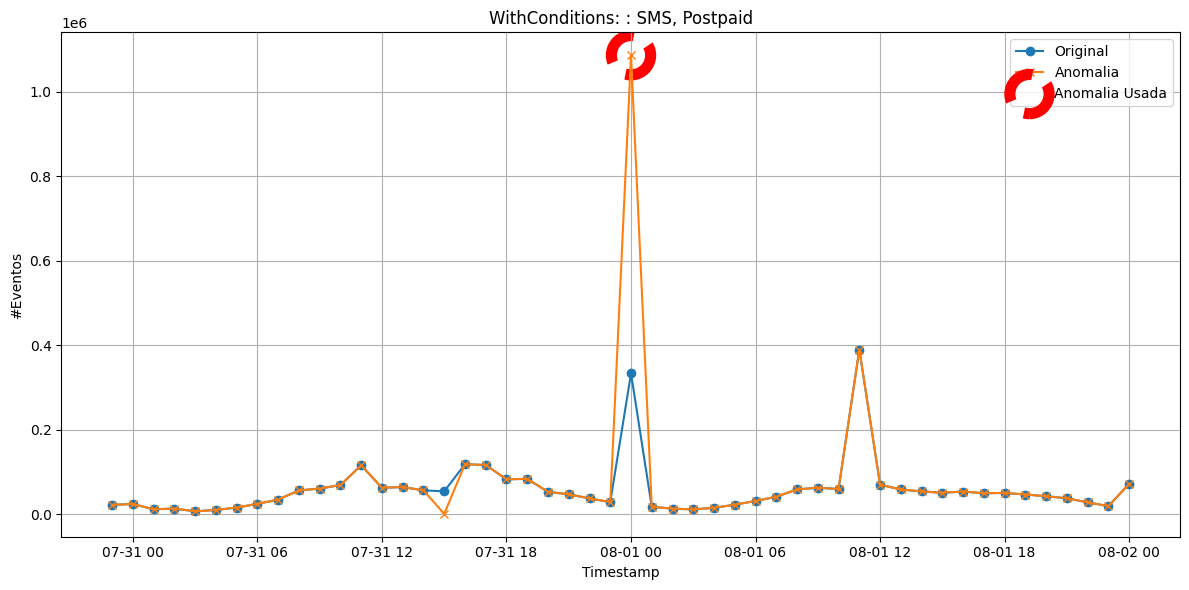

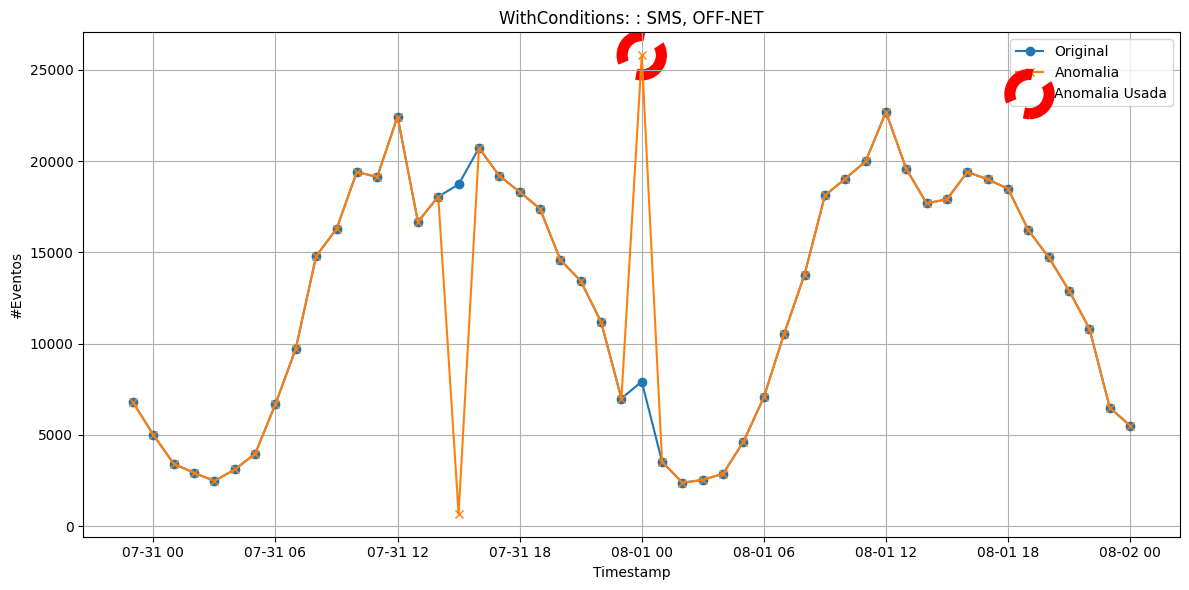

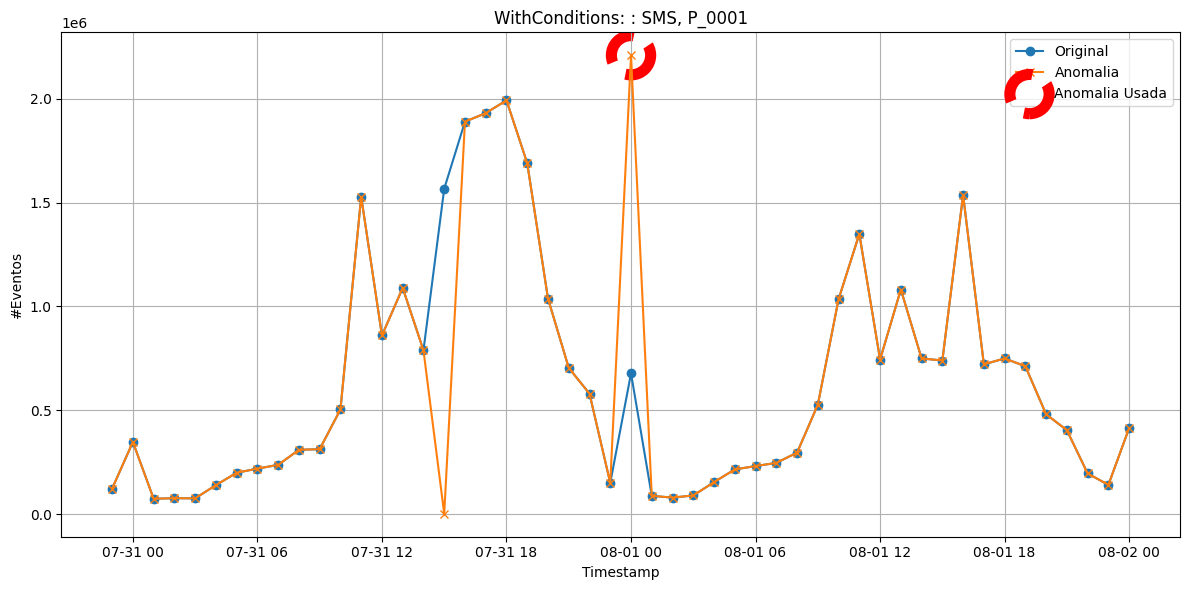

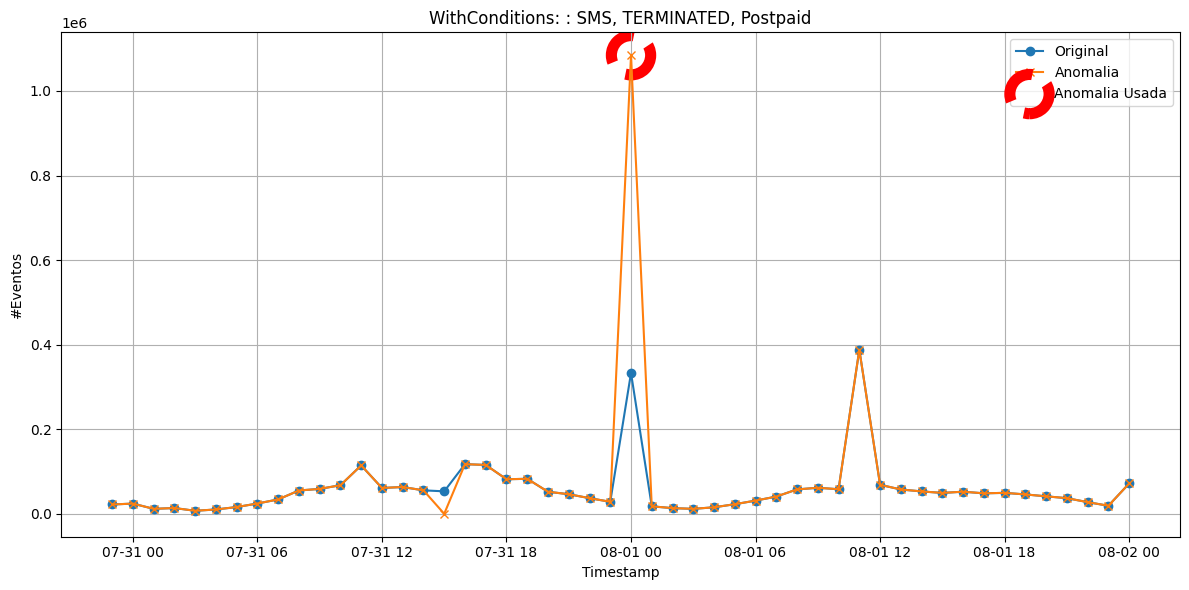

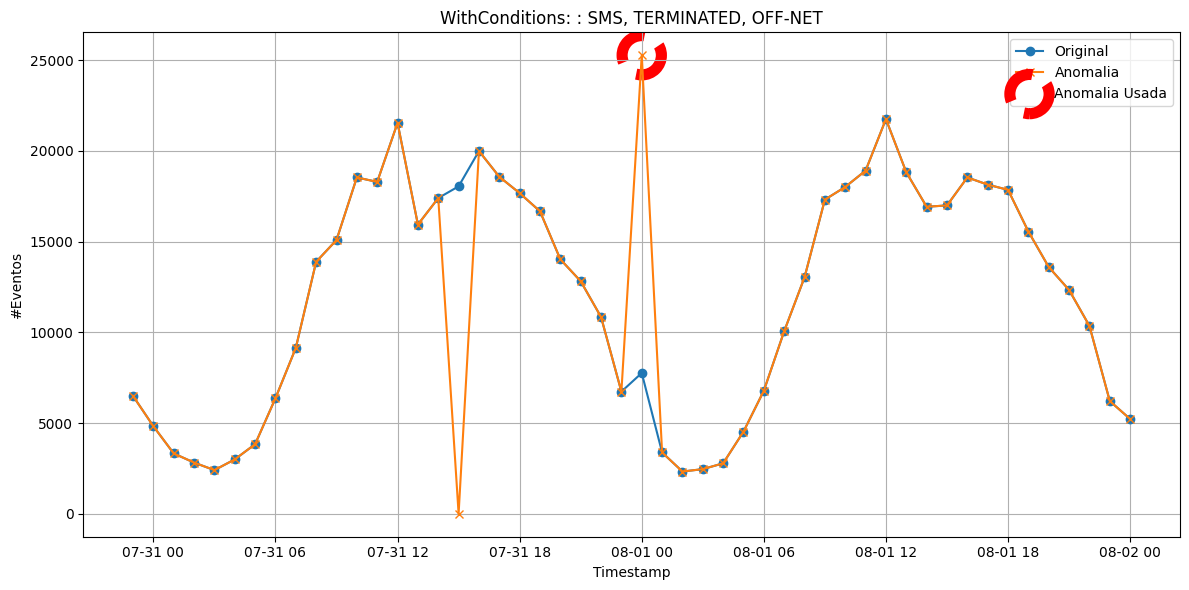

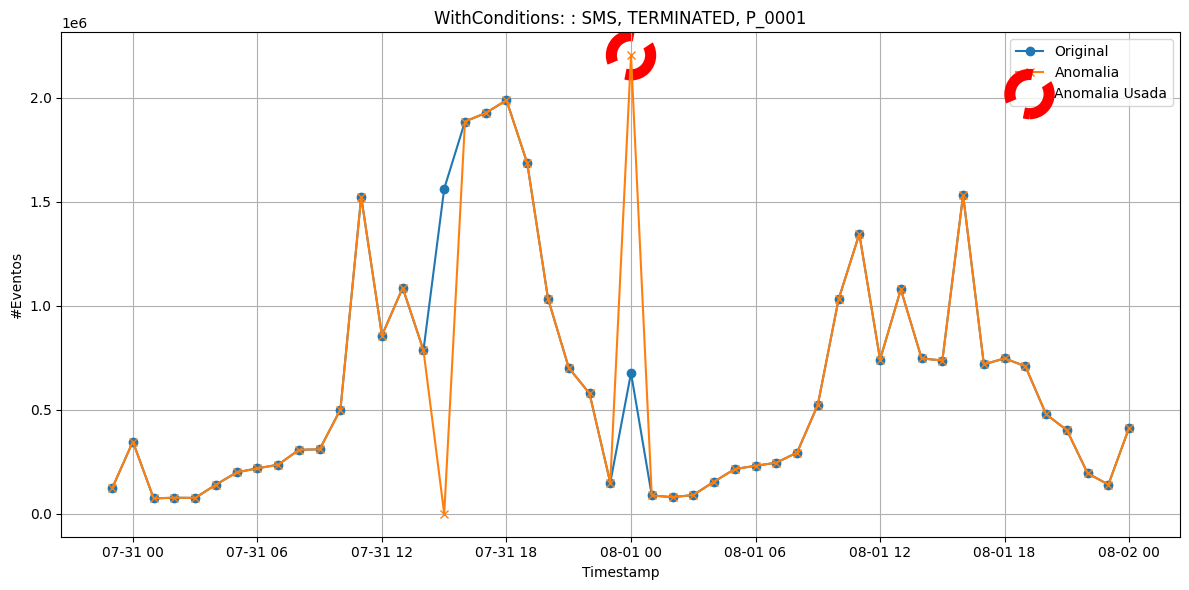

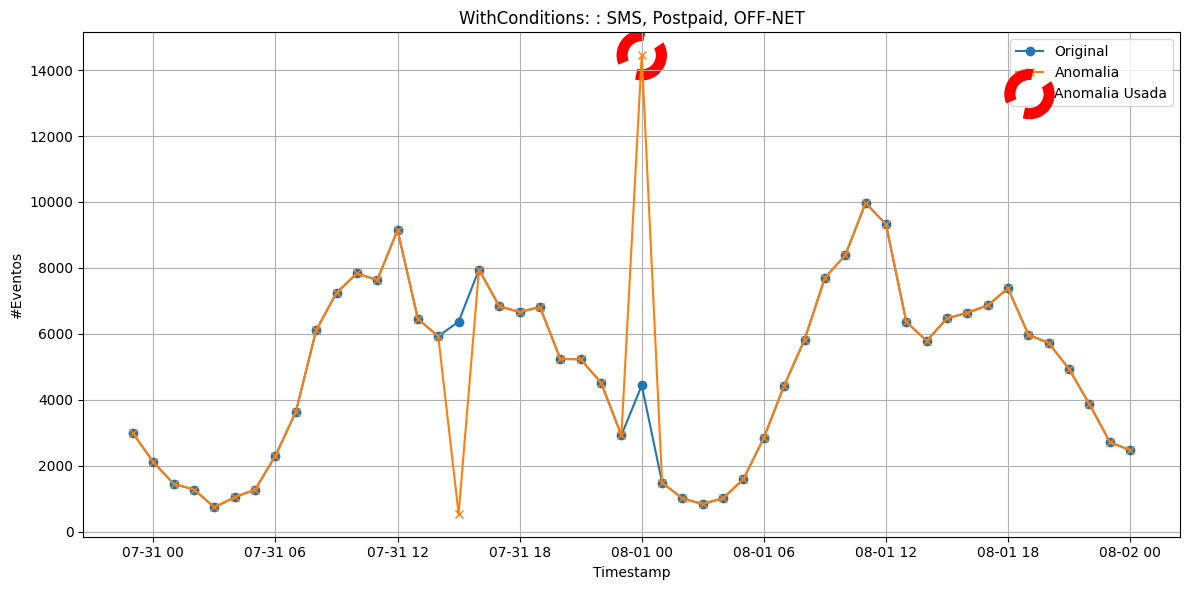

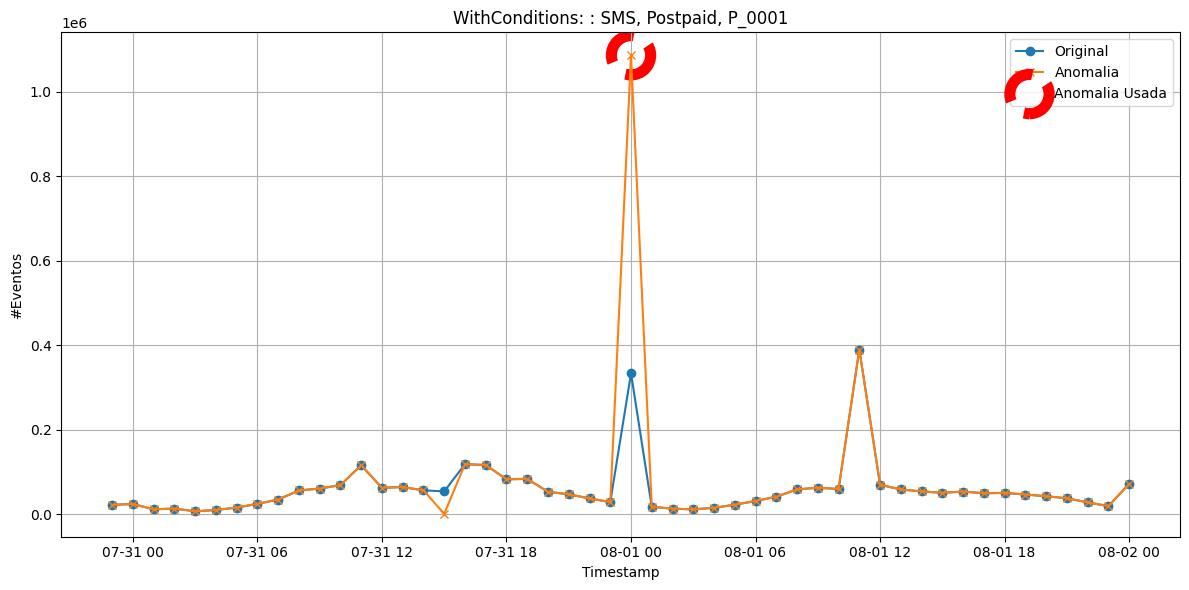

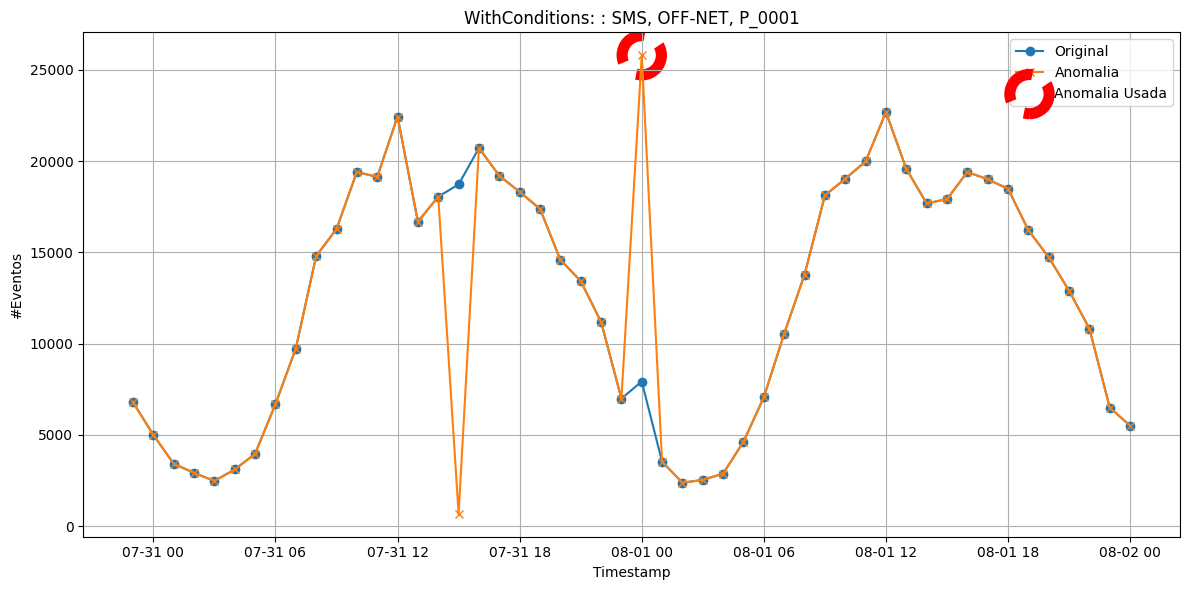

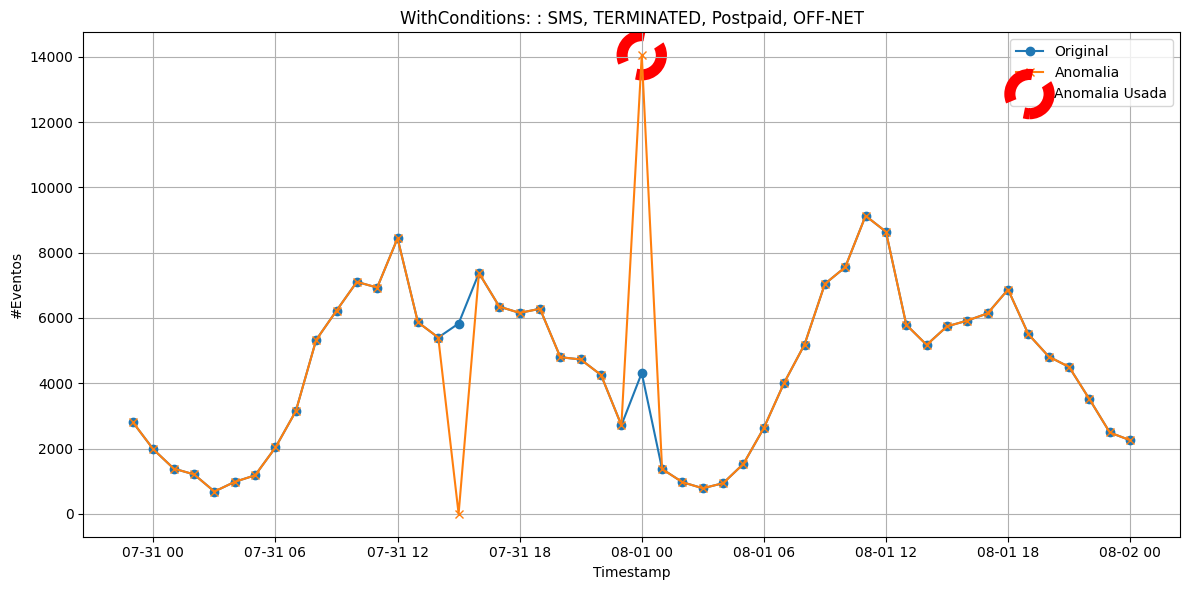

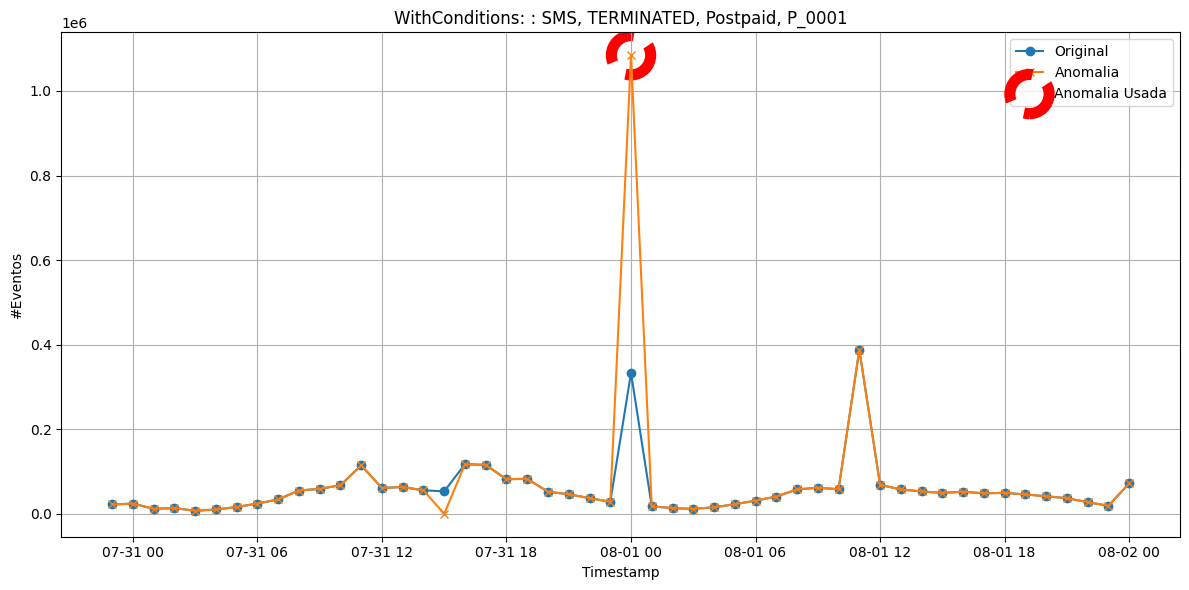

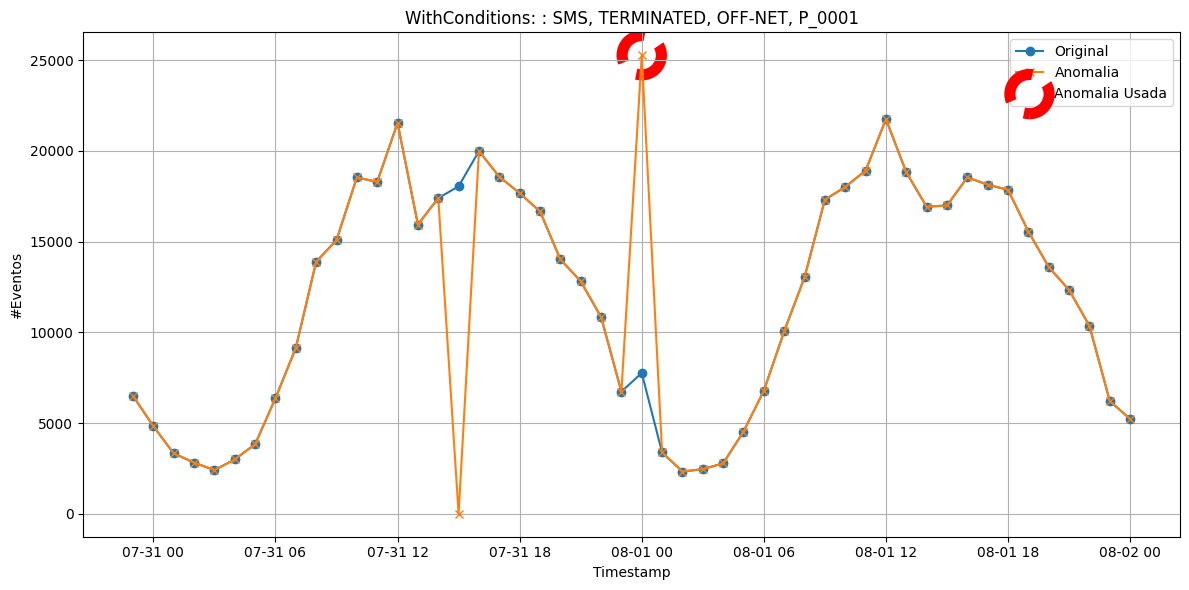

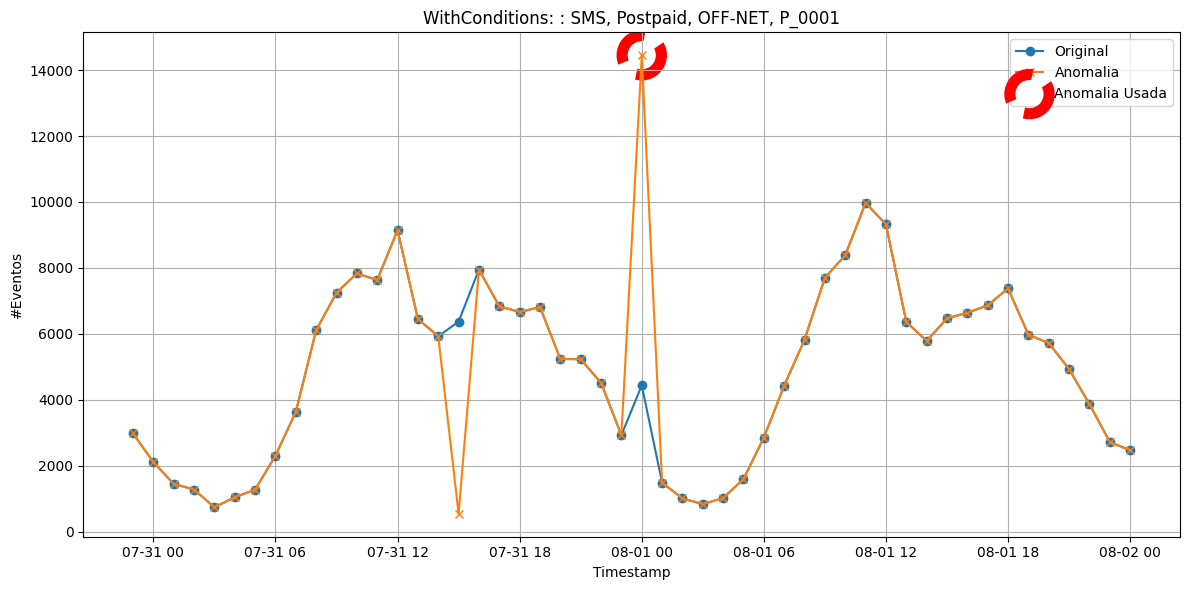

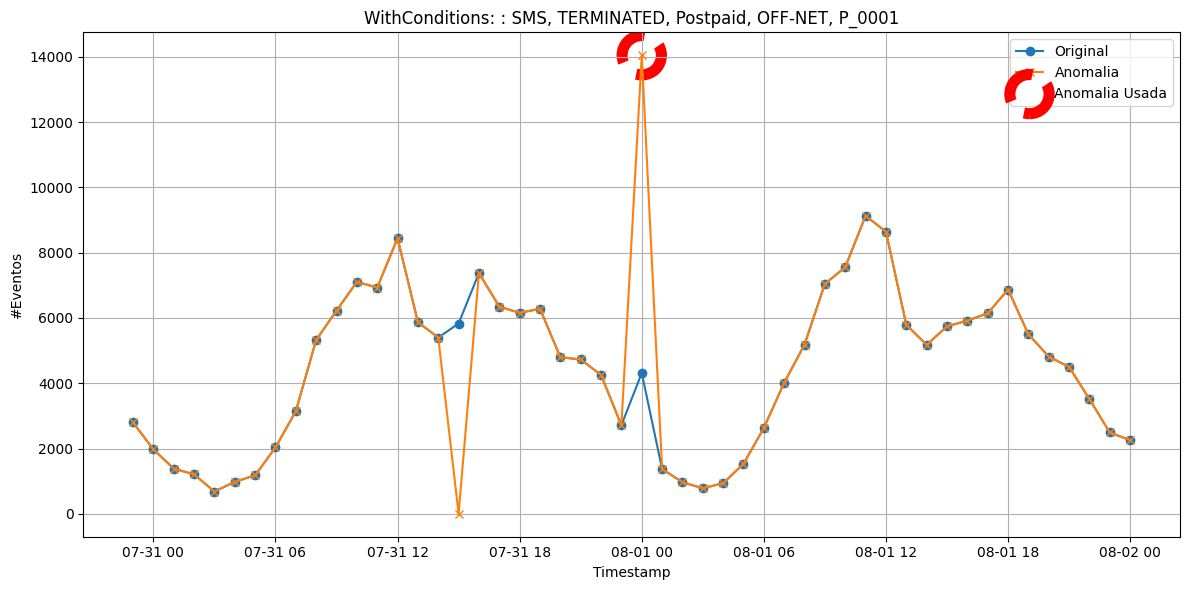

In [145]:
import itertools


def create_dictionaries(static_filter, filters, category_dict):
    all_combinations = []
    for r in range(1, len(filters) + 1):
        for combination in itertools.combinations(filters, r):
            current_dict = {}
            
            current_dict[static_filter[0]] = static_filter[1]
            for item in combination:
                category = category_dict.get(item)[0]
                
                if category:
                    # Assigning the filter to the correct category in the dictionary
                    
                    current_dict[category] = item
            if current_dict:  # Make sure the dictionary is not empty
                all_combinations.append(current_dict)
    return all_combinations

# Generating dictionaries
static_filter = [column, static_value]
resulting_dictionaries = create_dictionaries(static_filter, plot_filters, rt_available_categories)


# Print each generated dictionary
for dictionary in resulting_dictionaries:
    df_original_cond = filter_and_aggregate(df, dictionary, False)
    df_anomaly_cond = filter_and_aggregate(df_anomaly, dictionary, False)
    plot_figure(df_anomaly_cond, df_original_cond, center_ts, dictionary, "WithConditions: ")